Caffeine, Sleep, Well-Being, Work, and Lifestyle

NHANES 2017–2018 • Adults age 18+

Research question
How is caffeine intake associated with sleep, mental well-being, work patterns, and lifestyle behaviors among U.S. adults, and how do these associations vary across demographic groups?

Setup and file locations

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import kruskal

sns.set_theme(style = "whitegrid", context = "notebook")
pd.set_option("display.max_columns", 60)

# Update this path only if your project is stored somewhere else.
project_path = Path(r"C:\Users\Savio\OneDrive\Desktop\DS2\Project 3")
raw_candidates = [project_path / "data" / "raw", project_path / "raw", project_path]
raw_data_path = next((p for p in raw_candidates if p.exists() and any(p.glob("*.xpt"))), raw_candidates[0])
processed_path = project_path / "data" / "processed"
figures_path = project_path / "visualizations"
reports_path = project_path / "reports"
for folder in [processed_path, figures_path, reports_path]:
    folder.mkdir(parents = True, exist_ok = True)

Download (only if needed) and load the source files

These are the same 11 files previously agreed on. Existing raw files are not overwritten. The official NHANES files are downloaded only when missing.

In [2]:
source_files = {
    "Demographics": "DEMO_J.xpt",
    "Day 1 diet": "DR1TOT_J.xpt",
    "Day 2 diet": "DR2TOT_J.xpt",
    "Sleep": "SLQ_J.xpt",
    "Depression questionnaire": "DPQ_J.xpt",
    "Work": "OCQ_J.xpt",
    "Physical activity": "PAQ_J.xpt",
    "Alcohol": "ALQ_J.xpt",
    "Smoking": "SMQ_J.xpt",
    "Body measurements": "BMX_J.xpt",
    "Blood pressure": "BPX_J.xpt",}

DOWNLOAD_MISSING_FILES = True
if DOWNLOAD_MISSING_FILES:
    raw_data_path.mkdir(parents = True, exist_ok = True)
    for filename in source_files.values():
        target = raw_data_path / filename
        if not target.exists():
            url = f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/{filename}"
            try:
                urllib.request.urlretrieve(url, target)
                print("Downloaded:", filename)
            except Exception as error:
                print("Could not download", filename, "—", error)

data = {}
load_issues = []
for friendly_name, filename in source_files.items():
    file_path = raw_data_path / filename
    if not file_path.exists():
        load_issues.append(filename)
        continue
    data[friendly_name] = pd.read_sas(file_path, format = "xport", encoding = "utf-8")
    print(f"{friendly_name:24s} {data[friendly_name].shape}")

print(f"\nLoaded {len(data)} of {len(source_files)} files.")
if load_issues:
    print("Missing files:", load_issues)

Demographics             (9254, 46)
Day 1 diet               (8704, 168)
Day 2 diet               (8704, 85)
Sleep                    (6161, 11)
Depression questionnaire (5533, 11)
Work                     (6161, 10)
Physical activity        (5856, 17)
Alcohol                  (5533, 10)
Smoking                  (6724, 37)
Body measurements        (8704, 21)
Blood pressure           (8704, 21)

Loaded 11 of 11 files.


Quick data-quality check

This is the compact check we need at the start: file size, participant-ID uniqueness, and overall missingness. Detailed column inventories are saved separately instead of printed across dozens of screens.

In [3]:
file_check = pd.DataFrame([
    {"File": name, "Rows": frame.shape[0], "Columns": frame.shape[1],
     "Missing_IDs": frame["SEQN"].isna().sum() if "SEQN" in frame else np.nan,
     "Duplicate_IDs": frame["SEQN"].duplicated().sum() if "SEQN" in frame else np.nan,
     "Missing_cells_percent": frame.isna().sum().sum() / frame.size * 100}
    for name, frame in data.items()])
display(file_check.round(2))

# Save the complete variable list for reference without printing hundreds of rows.
variable_list = pd.DataFrame([
    {"Dataset": name, "Variable": variable, "Data_type": str(frame[variable].dtype)}
    for name, frame in data.items() for variable in frame.columns])
variable_list.to_csv(reports_path / "full_variable_list.csv", index = False)
print("Full variable list saved to reports/full_variable_list.csv")

,File,Rows,Columns,Missing_IDs,Duplicate_IDs,Missing_cells_percent
0,Demographics,9254,46,0,0,18.21
1,Day 1 diet,8704,168,0,0,43.57
2,Day 2 diet,8704,85,0,0,24.40
3,Sleep,6161,11,0,0,0.15
4,Depression questionnaire,5533,11,0,0,10.09
5,Work,6161,10,0,0,36.96
6,Physical activity,5856,17,0,0,40.77
7,Alcohol,5533,10,0,0,39.22
8,Smoking,6724,37,0,0,69.72
9,Body measurements,8704,21,0,0,55.10


Full variable list saved to reports/full_variable_list.csv



Variable guide: what is actually used?

This is the map for the project. Primary variables are used to answer the research question; adjustment variables are included in the main regression models; descriptive variables are summarized or visualized but are not automatically predictors; and survey design variables are used for weights/variance approximation.

| Research role | Plain-English name | NHANES source code | How it is used |
|---|---|---|---|
| Main exposure | Caffeine intake, Day 1 | `DR1TCAFF` | Main regression exposure; caffeine-group plots |
| Sensitivity exposure | Caffeine intake, Day 2 | `DR2TCAFF` | Compare recall days |
| Sensitivity exposure | Two-day caffeine average | Derived from `DR1TCAFF`, `DR2TCAFF` | Alternative exposure sensitivity model |
| Outcome | Weekday sleep duration | `SLD012` | Outcome for main regression and plots |
| Outcome | Sleep on nonworkdays | `SLD013` | Descriptive plot only in current version |
| Outcome | Depression symptom total (9-item screening scale) | `DPQ010`–`DPQ090` | Outcome for main regression and plots; score ranges 0–27 |
| Outcome | Work hours last week | `OCQ180` | Outcome for main regression and plots |
| Adjustment | Age | `RIDAGEYR` | Main regression; age-group comparisons |
| Adjustment | Sex category | `RIAGENDR` | Main regression; comparisons |
| Adjustment | Race/ethnicity | `RIDRETH1` | Main regression; comparisons |
| Adjustment | Education | `DMDEDUC2` | Main regression |
| Adjustment | Family income-to-poverty ratio | `INDFMPIR` | Main regression |
| Survey design | Day 1 dietary weight | `WTDRD1` | Weighted main models (approximate inference) |
| Survey design | Day 2 dietary weight | `WTDR2D` | Two-day sensitivity model when available |
| Survey design | Strata | `SDMVSTRA` | Required for full complex-survey inference; currently not incorporated in approximate regression |
| Survey design | Primary sampling unit | `SDMVPSU` | Clustered standard errors in approximate regression |
| Descriptive health | BMI | `BMXBMI` | Availability/summary table, not primary model |
| Descriptive health | Waist circumference | `BMXWAIST` | Availability/summary table, not primary model |
| Descriptive health | Height and weight | `BMXHT`, `BMXWT` | Variable availability audit |
| Descriptive health | Blood pressure readings | `BPXSY1`–`BPXSY4`, `BPXDI1`–`BPXDI4` | Availability audit only; no averaged BP measure currently modeled |
| Lifestyle description | Physical activity and sedentary behavior | `PAQ605`, `PAQ620`, `PAQ635`, `PAQ650`, `PAQ665`, `PAD680` | Availability audit only; not currently predictors |
| Lifestyle description | Alcohol use questionnaire | `ALQ` variables listed in audit cell | Availability audit only; not currently predictors |
| Lifestyle description | Smoking questionnaire | `SMQ` variables listed in audit cell | Availability audit only; not currently predictors |

Important: The notebook loads 11 files, but loading a file does not mean every column is used in analysis. The lifestyle questionnaire variables are currently audited for availability only; they are not included as model controls. This distinction is made explicit to avoid implying otherwise.


Merge files into one participant table

All NHANES files use `SEQN`, the participant ID. We start with demographics and left-join the other files so that demographics participants are retained. The code stops if a file has duplicate IDs, which could accidentally duplicate participants.

In [4]:
merge_order = list(source_files)
merged = data["Demographics"].copy()
for name in merge_order[1:]:
    if name not in data:
        print("Skipping missing file:", name)
        continue
    right = data[name].copy()
    if right["SEQN"].duplicated().any():
        raise ValueError(f"Duplicate participant IDs in {name}")
    overlapping = (set(merged.columns) & set(right.columns)) - {"SEQN"}
    right = right.rename(columns = {c: f"{c}_{name.replace(' ', '_')}" for c in overlapping})
    merged = merged.merge(right, on = "SEQN", how = "left", validate = "one_to_one")
print("Merged participants:", len(merged))
print("Merged columns:", merged.shape[1])
print("ID duplicates after merge:", merged.SEQN.duplicated().sum())

Merged participants: 9254
Merged columns: 427
ID duplicates after merge: 0


Select adults and create understandable analysis variables

This section keeps the merged data intact and creates an adult-only working copy. The short NHANES names are kept as source columns, while analysis variables use readable names.

Depression symptom score: the PHQ-9 is a nine-question symptom scale. Each valid item is scored 0–3 and summed (0–27); invalid/refused/don't-know codes are treated as missing. This score is a screening measure, not a diagnosis.

In [5]:
adult_data = merged.loc[pd.to_numeric(merged["RIDAGEYR"], errors = "coerce") >= 18].copy()
print("Adults (18+):", len(adult_data), "of", len(merged), "participants")

# Caffeine: amount consumed on each dietary recall day (mg). Tiny import artifacts, if present, are recoded to zero.
for source, readable in [("DR1TCAFF", "caffeine_day1_mg"), ("DR2TCAFF", "caffeine_day2_mg")]:
    adult_data[readable] = pd.to_numeric(adult_data[source], errors = "coerce")
    tiny = (adult_data[readable] > 0) & (adult_data[readable] < 1e-50)
    print(readable, "tiny values corrected:", int(tiny.sum()))
    adult_data.loc[tiny, readable] = 0
    adult_data.loc[adult_data[readable] < 0, readable] = np.nan
adult_data["caffeine_two_day_average_mg"] = adult_data[["caffeine_day1_mg", "caffeine_day2_mg"]].mean(axis = 1, skipna = False)

# Sleep: invalid/special codes outside the plausible 0–24 hour range become missing.
adult_data["weekday_sleep_hours"] = pd.to_numeric(adult_data["SLD012"], errors = "coerce")
adult_data["weekday_sleep_hours"] = adult_data["weekday_sleep_hours"].where(adult_data["weekday_sleep_hours"].between(0,24))
adult_data["nonworkday_sleep_hours"] = pd.to_numeric(adult_data["SLD013"], errors = "coerce")
adult_data["nonworkday_sleep_hours"] = adult_data["nonworkday_sleep_hours"].where(adult_data["nonworkday_sleep_hours"].between(0,24))

# PHQ-9 depression symptom score: require all nine valid items.
phq_items = [f"DPQ0{i}0" for i in range(1,10)]
if all(item in adult_data.columns for item in phq_items):
    for item in phq_items:
        adult_data[item] = pd.to_numeric(adult_data[item], errors = "coerce")
        adult_data.loc[~adult_data[item].isin([0,1,2,3]), item] = np.nan
    adult_data["depression_symptom_score"] = adult_data[phq_items].sum(axis = 1, min_count = 9)
else:
    print("PHQ-9 items not all present; score was not calculated.")

# Work hours: convert special refusal/unknown codes and values beyond a week to missing.
adult_data["work_hours_last_week"] = pd.to_numeric(adult_data["OCQ180"], errors = "coerce")
adult_data.loc[adult_data["work_hours_last_week"].isin([77777,99999]), "work_hours_last_week"] = np.nan
adult_data["work_hours_last_week"] = adult_data["work_hours_last_week"].where(adult_data["work_hours_last_week"].between(0,168))

# Readable age groups for charts.
adult_data["age_group"] = pd.cut(adult_data["RIDAGEYR"], bins = [18,30,45,60,80], labels = ["18–29","30–44","45–59","60–79"], right = False).astype("object")
adult_data.loc[adult_data["RIDAGEYR"] >= 80, "age_group"] = "80+"
print("Working adult dataset shape:", adult_data.shape)

Adults (18+): 5856 of 9254 participants
caffeine_day1_mg tiny values corrected: 778
caffeine_day2_mg tiny values corrected: 823
Working adult dataset shape: (5856, 435)


Simple cleaning summary

A compact table shows how many usable values each main measure has. This helps readers understand why sample sizes vary between analyses.

In [6]:
main_variables = {
    "Day 1 caffeine (mg)": "caffeine_day1_mg",
    "Day 2 caffeine (mg)": "caffeine_day2_mg",
    "Two-day average caffeine (mg)": "caffeine_two_day_average_mg",
    "Weekday sleep (hours)": "weekday_sleep_hours",
    "Nonworkday sleep (hours)": "nonworkday_sleep_hours",
    "Depression symptom score (0–27)": "depression_symptom_score",
    "Work hours last week": "work_hours_last_week",
    "BMI": "BMXBMI", "Waist circumference (cm)": "BMXWAIST",}
summary_rows = []
for label, col in main_variables.items():
    if col in adult_data:
        vals = pd.to_numeric(adult_data[col], errors = "coerce")
        summary_rows.append({"Measure":label,"Available N":vals.notna().sum(),"Missing N":vals.isna().sum(),
                            "Mean":vals.mean(),"Median":vals.median(),"Min":vals.min(),"Max":vals.max()})
cleaning_summary = pd.DataFrame(summary_rows)
display(cleaning_summary.round(2))
cleaning_summary.to_csv(reports_path / "cleaning_summary.csv", index = False)

,Measure,Available N,Missing N,Mean,Median,Min,Max
0,Day 1 caffeine (mg),4983,873,140.98,94.0,0.0,4320.0
1,Day 2 caffeine (mg),4339,1517,126.22,82.0,0.0,5040.0
2,Two-day average caffeine (mg),4339,1517,133.78,91.5,0.0,4680.0
3,Weekday sleep (hours),5809,47,7.64,8.0,2.0,14.0
4,Nonworkday sleep (hours),5800,56,8.31,8.0,2.0,14.0
5,Depression symptom score (0–27),36,5820,18.25,18.0,10.0,25.0
6,Work hours last week,3067,2789,39.29,40.0,5.0,80.0
7,BMI,5434,422,29.69,28.5,14.2,86.2
8,Waist circumference (cm),5184,672,100.16,98.9,56.4,169.5


Visual exploration: caffeine intake

Caffeine intake usually has a long right tail, so the first graph shows the original milligram scale and the second shows a log-scaled view. The log view is for visualization only; it does not change the stored caffeine values.

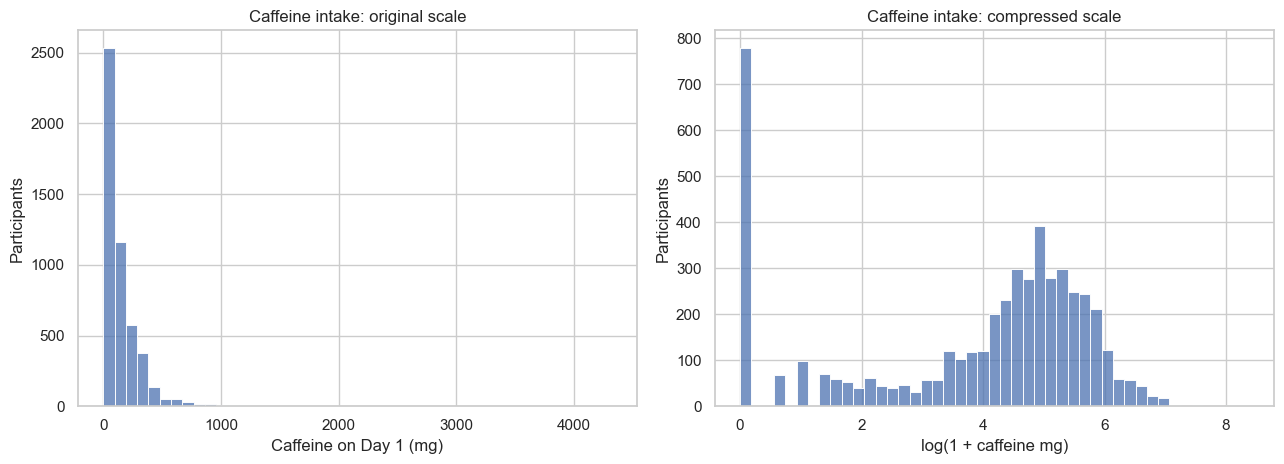

Non-missing caffeine observations: 4983
Median caffeine (mg): 94.0  | Mean: 141.0


In [7]:
caffeine = adult_data["caffeine_day1_mg"].dropna()
fig, axes = plt.subplots(1,2,figsize = (13,4.8))
sns.histplot(caffeine, bins = 45, ax = axes[0])
axes[0].set(title = "Caffeine intake: original scale", xlabel = "Caffeine on Day 1 (mg)", ylabel = "Participants")
sns.histplot(np.log1p(caffeine), bins = 45, ax = axes[1])
axes[1].set(title = "Caffeine intake: compressed scale", xlabel = "log(1 + caffeine mg)", ylabel = "Participants")
plt.tight_layout(); plt.savefig(figures_path / "caffeine_distribution.png", dpi = 180, bbox_inches = "tight"); plt.show()
print("Non-missing caffeine observations:", len(caffeine))
print("Median caffeine (mg):", round(caffeine.median(),1), " | Mean:", round(caffeine.mean(),1))

Visual exploration: caffeine across recall days

Day 2 and the two-day average are useful checks, but not everyone completed both recall days. This figure compares the distributions without implying that the two days are identical samples.

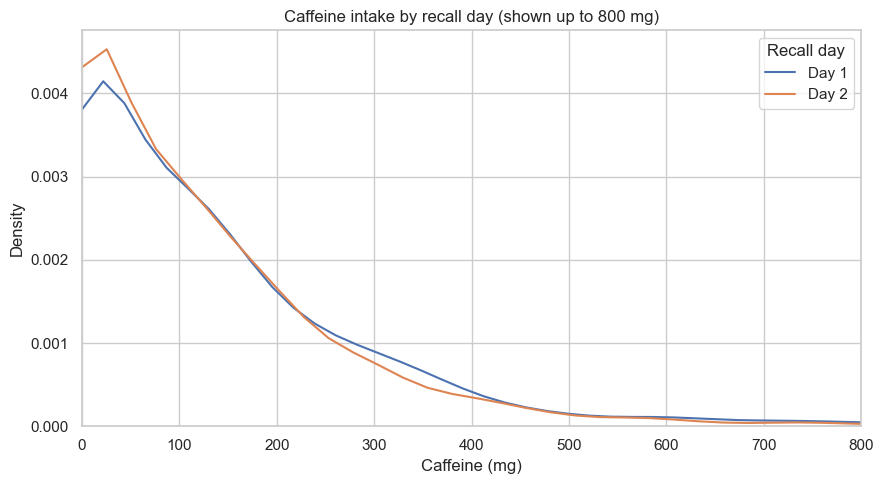

In [8]:
fig, ax = plt.subplots(figsize = (9,5))
for column, label in [("caffeine_day1_mg","Day 1"),("caffeine_day2_mg","Day 2")]:
    sns.kdeplot(adult_data[column].dropna(), ax = ax, label = label, cut = 0)
ax.set_xlim(0,800); ax.set(title = "Caffeine intake by recall day (shown up to 800 mg)", xlabel = "Caffeine (mg)", ylabel = "Density")
ax.legend(title = "Recall day"); plt.tight_layout(); plt.savefig(figures_path / "caffeine_day_comparison.png", dpi = 180, bbox_inches = "tight"); plt.show()

Visual exploration: sleep, depression symptoms, and work

The three outcomes are displayed separately because they have different units and meanings. Work hours are available only for participants with valid responses to the work question.

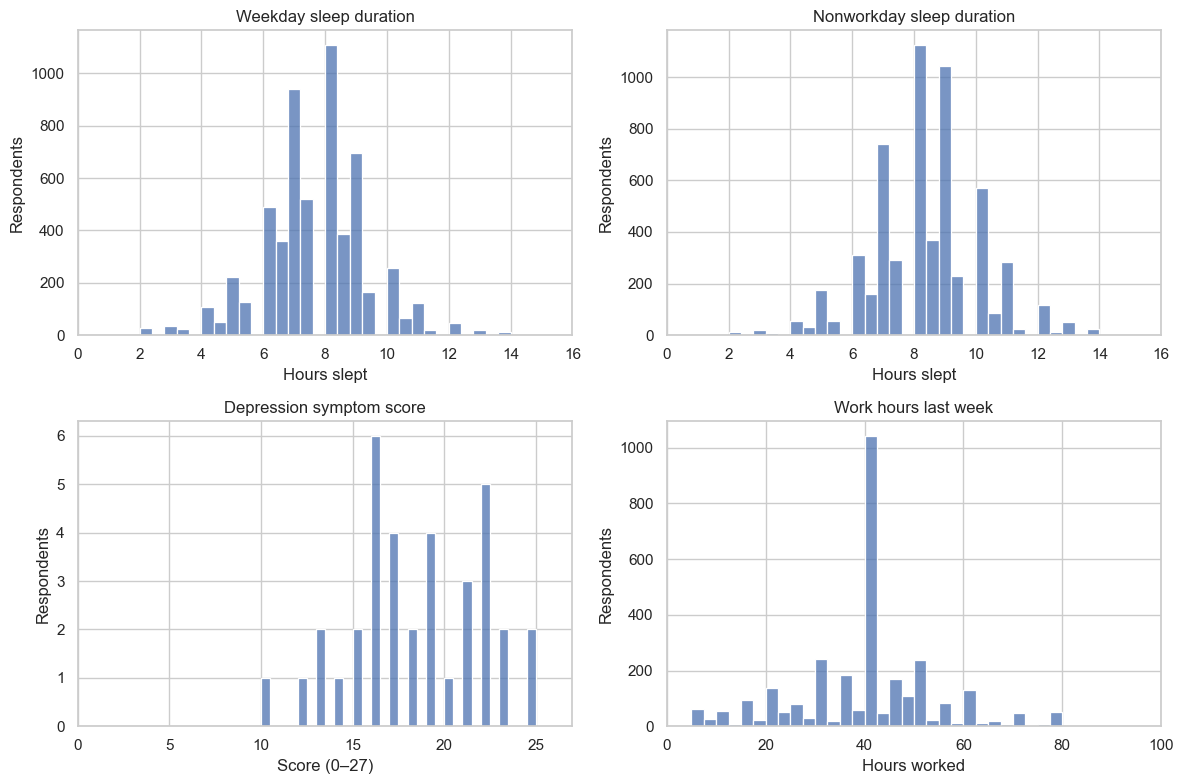

In [9]:
plot_specs = [
    ("weekday_sleep_hours", "Weekday sleep duration", "Hours slept", (0,16)),
    ("nonworkday_sleep_hours", "Nonworkday sleep duration", "Hours slept", (0,16)),
    ("depression_symptom_score", "Depression symptom score", "Score (0–27)", (0,27)),
    ("work_hours_last_week", "Work hours last week", "Hours worked", (0,100)),]
fig, axes = plt.subplots(2,2,figsize = (12,8))
for ax, (col,title,xlabel,xlim) in zip(axes.flat, plot_specs):
    values = adult_data[col].dropna()
    sns.histplot(values, bins = 30, ax = ax)
    ax.set(title = title, xlabel = xlabel, ylabel = "Respondents", xlim = xlim)
plt.tight_layout(); plt.savefig(figures_path / "main_outcomes_distributions.png", dpi = 180, bbox_inches = "tight"); plt.show()

Relationship plots: caffeine and each research outcome

These plots show the raw association between caffeine intake and each outcome. Points are lightly sampled to reduce overplotting; the line is a simple linear trend for visualization. These are unadjusted plots —demographics and other confounders are not controlled here. They help us see shape, spread, and possible nonlinear patterns before regression.


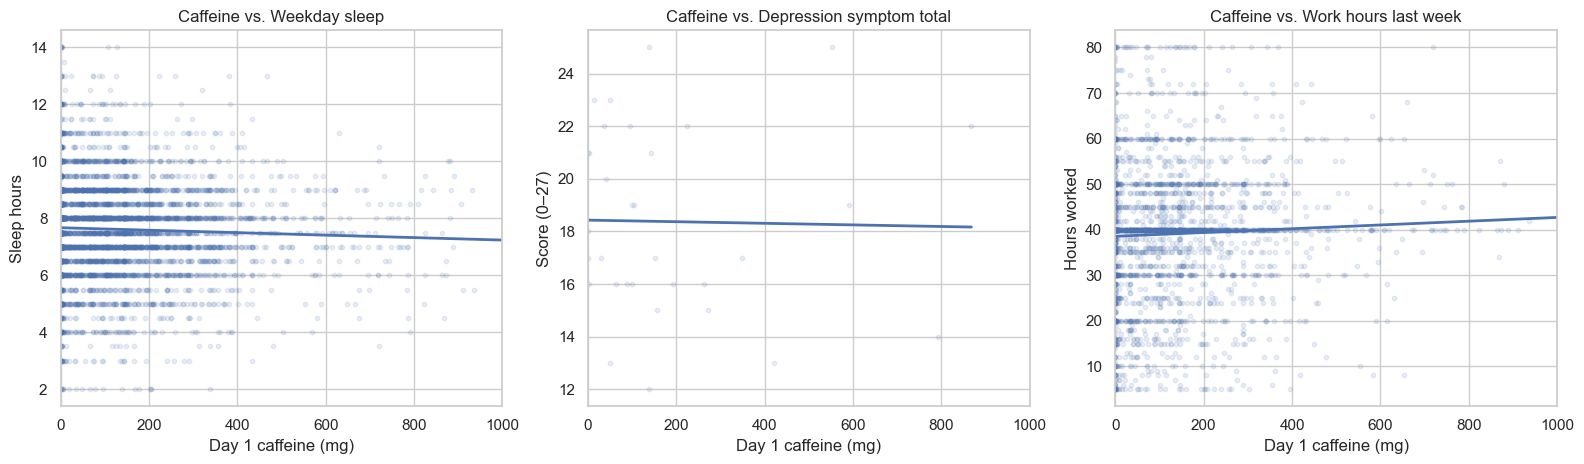

These are exploratory raw relationships; adjusted estimates come from the regression section.


In [10]:

relationship_specs = [
    ("weekday_sleep_hours", "Weekday sleep", "Sleep hours"),
    ("depression_symptom_score", "Depression symptom total", "Score (0–27)"),
    ("work_hours_last_week", "Work hours last week", "Hours worked"),]
fig, axes = plt.subplots(1, 3, figsize = (16, 4.8))
for ax, (outcome, title, y_label) in zip(axes, relationship_specs):
    plot_data = adult_data[["caffeine_day1_mg", outcome]].dropna()
    if len(plot_data) > 6000:
        plot_data = plot_data.sample(6000, random_state = 42)
    ax.scatter(plot_data["caffeine_day1_mg"], plot_data[outcome], alpha = 0.12, s = 10)
    if len(plot_data) >= 2 and plot_data["caffeine_day1_mg"].nunique() > 1:
        x = plot_data["caffeine_day1_mg"].to_numpy()
        y = plot_data[outcome].to_numpy()
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(0, min(plot_data["caffeine_day1_mg"].max(), 1000), 100)
        ax.plot(x_line, intercept + slope*x_line, linewidth = 2)
    ax.set(title = f"Caffeine vs. {title}", xlabel = "Day 1 caffeine (mg)", ylabel = y_label, xlim = (0,1000))
plt.tight_layout()
plt.savefig(figures_path / "caffeine_outcome_relationships.png", dpi = 180, bbox_inches = "tight")
plt.show()
print("These are exploratory raw relationships; adjusted estimates come from the regression section.")


Focus graph: caffeine and depression symptom score

This is shown separately so the depression analysis is easy to locate. The scatter points are individual participants (sampled if the dataset is large), and the line is an unadjusted linear trend. The regression table and predicted curve are the adjusted analyses.

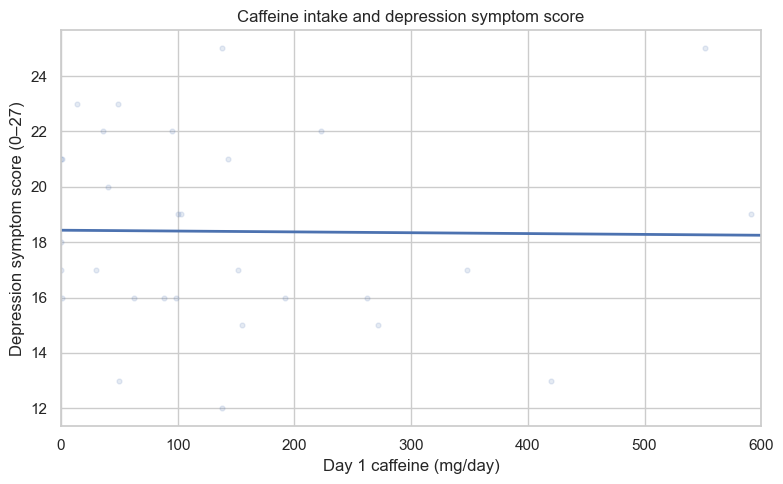

Depression plot sample: 32 participants; data available: 32.


In [11]:
# Dedicated depression-symptom relationship plot (unadjusted)
depression_plot_data = adult_data[["caffeine_day1_mg", "depression_symptom_score"]].dropna()
if len(depression_plot_data) >= 2:
    plot_sample = depression_plot_data.sample(min(6000, len(depression_plot_data)), random_state = 42)
    fig, ax = plt.subplots(figsize = (8, 5))
    ax.scatter(plot_sample["caffeine_day1_mg"], plot_sample["depression_symptom_score"], alpha = 0.14, s = 12)
    if plot_sample["caffeine_day1_mg"].nunique() > 1:
        slope, intercept = np.polyfit(plot_sample["caffeine_day1_mg"], plot_sample["depression_symptom_score"], 1)
        line_x = np.linspace(0, min(plot_sample["caffeine_day1_mg"].max(), 600), 100)
        ax.plot(line_x, intercept + slope * line_x, linewidth = 2)
    ax.set(title = "Caffeine intake and depression symptom score", xlabel = "Day 1 caffeine (mg/day)", ylabel = "Depression symptom score (0–27)", xlim = (0, 600))
    plt.tight_layout()
    plt.savefig(figures_path / "depression_caffeine_relationship.png", dpi = 180, bbox_inches = "tight")
    plt.show()
    print(f"Depression plot sample: {len(plot_sample):,} participants; data available: {len(depression_plot_data):,}.")
else:
    print("Depression graph not created: fewer than two complete observations or depression score is unavailable.")

Compare caffeine intake groups

We use four groups based on the distribution of Day 1 caffeine intake. Quartiles are a descriptive device: Q1 means the lowest-intake group and Q4 the highest. Ties are handled by ranking before dividing into four equal-sized groups. This grouping is separate from the continuous caffeine variable used in regression.

caffeine_day1_mg                weekday_sleep_hours        \
                          count    mean median               count  mean   
caffeine_group                                                             
Q1 Lowest                  1246    1.47    0.0                1231  7.66   
Q2                         1246   50.69   50.0                1231  7.70   
Q3                         1245  136.36  137.0                1240  7.59   
Q4 Highest                 1246  375.40  297.5                1243  7.49   

                      depression_symptom_score                \
               median                    count   mean median   
caffeine_group                                                 
Q1 Lowest         8.0                        5  18.60   18.0   
Q2                8.0                        8  18.75   18.5   
Q3                7.5                       10  18.20   18.0   
Q4 Highest        7.5                        9  18.11   17.0   

               work_hours_last_week                
                              count   mean median  
caffeine_group                                     
Q1 Lowest                       623  37.80   40.0  
Q2                              665  38.54   40.0  
Q3                              692  40.21   40.0  
Q4 Highest                      675  39.88   40.0

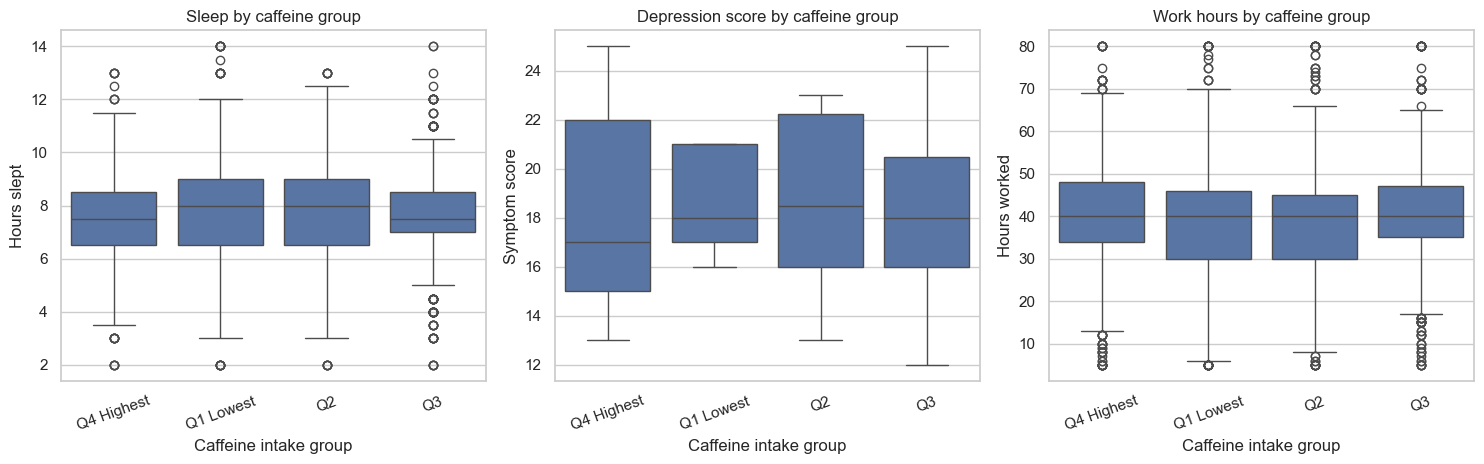

In [12]:
has_caffeine = adult_data["caffeine_day1_mg"].notna()
ranked_caffeine = adult_data.loc[has_caffeine, "caffeine_day1_mg"].rank(method = "first")
adult_data["caffeine_group"] = pd.NA
adult_data.loc[has_caffeine, "caffeine_group"] = pd.qcut(ranked_caffeine, 4, labels = ["Q1 Lowest","Q2","Q3","Q4 Highest"]).astype(str)
quartile_summary = adult_data.groupby("caffeine_group", observed = False)[["caffeine_day1_mg","weekday_sleep_hours","depression_symptom_score","work_hours_last_week"]].agg(["count","mean","median"])
display(quartile_summary.round(2))

fig, axes = plt.subplots(1,3,figsize = (15,4.8))
for ax, outcome, title, ylabel in zip(axes, ["weekday_sleep_hours","depression_symptom_score","work_hours_last_week"],
    ["Sleep by caffeine group","Depression score by caffeine group","Work hours by caffeine group"],
    ["Hours slept","Symptom score","Hours worked"]):
    sns.boxplot(data = adult_data, x = "caffeine_group", y = outcome, ax = ax)
    ax.set(title = title, xlabel = "Caffeine intake group", ylabel = ylabel)
    ax.tick_params(axis = "x", rotation = 20)
plt.tight_layout(); plt.savefig(figures_path / "outcomes_by_caffeine_quartile.png", dpi = 180, bbox_inches = "tight"); plt.show()

Demographic comparisons

These graphs describe how caffeine intake varies across age categories and NHANES sex groups. Sex codes are labeled in the chart rather than shown as numeric values. Race/ethnicity is available in the data as NHANES categories; labels are assigned below for the standard 2017–2018 category codes.

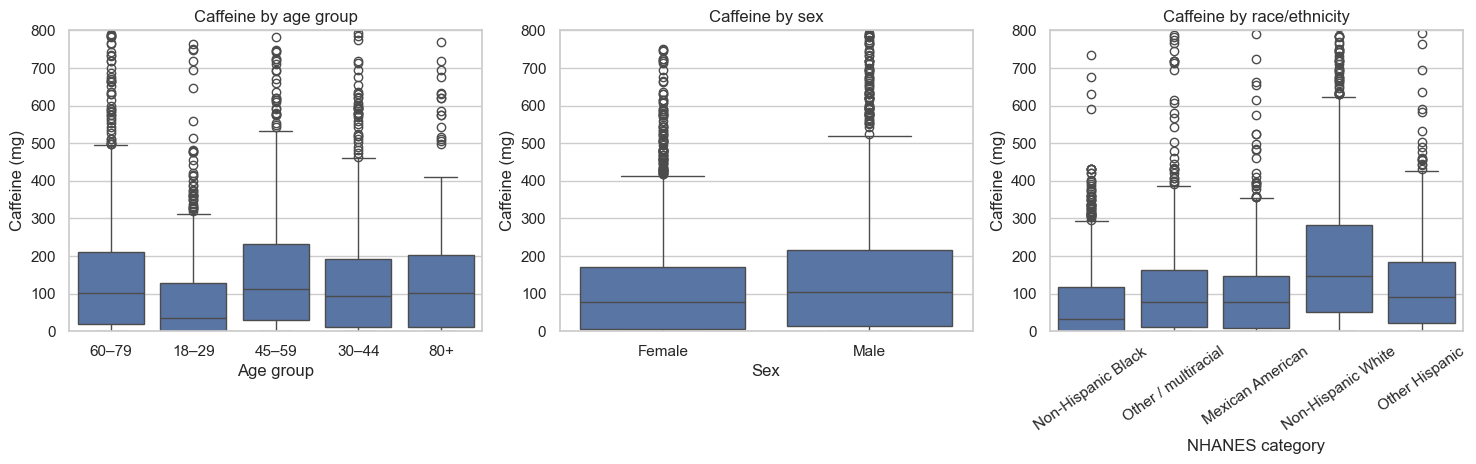

Group sample sizes:


sex_label,Female,Male
age_group,,
18–29,481,454
30–44,593,492
45–59,600,552
60–79,725,778
80+,158,150


In [13]:
adult_data["sex_label"] = adult_data["RIAGENDR"].map({1:"Male", 2:"Female"})
adult_data["race_ethnicity_label"] = adult_data["RIDRETH1"].map({1:"Mexican American", 2:"Other Hispanic", 3:"Non-Hispanic White", 4:"Non-Hispanic Black", 5:"Other / multiracial"})
fig, axes = plt.subplots(1,3,figsize = (15, 4.8))
sns.boxplot(data = adult_data, x = "age_group", y = "caffeine_day1_mg", ax = axes[0]); axes[0].set(title = "Caffeine by age group", xlabel = "Age group", ylabel = "Caffeine (mg)", ylim = (0,800))
sns.boxplot(data = adult_data, x = "sex_label", y = "caffeine_day1_mg", ax = axes[1]); axes[1].set(title = "Caffeine by sex", xlabel = "Sex", ylabel = "Caffeine (mg)", ylim = (0,800))
sns.boxplot(data = adult_data, x = "race_ethnicity_label", y = "caffeine_day1_mg", ax = axes[2]); axes[2].set(title = "Caffeine by race/ethnicity", xlabel = "NHANES category", ylabel = "Caffeine (mg)", ylim = (0,800)); axes[2].tick_params(axis = "x", rotation = 35)
plt.tight_layout(); plt.savefig(figures_path / "caffeine_demographics.png", dpi = 180, bbox_inches = "tight"); plt.show()

print("Group sample sizes:")
display(adult_data.groupby(["age_group","sex_label"], observed = False)["caffeine_day1_mg"].count().unstack().fillna(0))

Other lifestyle measures (compact audit)

These domains are retained to support the broader research question, but we do not treat every questionnaire code as a numeric scale. The table reports availability only; later analyses can focus on variables after codebook review. BMI and waist circumference are summarized as numeric measures.

In [14]:
lifestyle_code_map = {
    "Physical activity / sedentary": ["PAQ605","PAQ620","PAQ635","PAQ650","PAQ665","PAD680"],
    "Alcohol": ["ALQ101","ALQ120","ALQ130","ALQ151","ALQ160","ALQ170"],
    "Smoking": ["SMQ020","SMQ040","SMQ050","SMQ078","SMQ621","SMQ660"],
    "Body measurements": ["BMXBMI","BMXWAIST","BMXHT","BMXWT"],
    "Blood pressure": [f"BPXSY{i}" for i in range(1,5)] + [f"BPXDI{i}" for i in range(1,5)],}
rows = []
for domain, variables in lifestyle_code_map.items():
    for variable in variables:
        if variable in adult_data.columns:
            rows.append({"Domain":domain,"NHANES source variable":variable,"Nonmissing N":adult_data[variable].notna().sum(),"Missing %":adult_data[variable].isna().mean()*100})
lifestyle_availability = pd.DataFrame(rows)
display(lifestyle_availability.round(1))
lifestyle_availability.to_csv(reports_path / "lifestyle_variable_availability.csv", index = False)

,Domain,NHANES source variable,Nonmissing N,Missing %
0,Physical activity / sedentary,PAQ605,5856,0.0
1,Physical activity / sedentary,PAQ620,5856,0.0
2,Physical activity / sedentary,PAQ635,5856,0.0
3,Physical activity / sedentary,PAQ650,5856,0.0
4,Physical activity / sedentary,PAQ665,5856,0.0
5,Physical activity / sedentary,PAD680,5846,0.2
6,Alcohol,ALQ130,3495,40.3
7,Alcohol,ALQ151,4544,22.4
8,Alcohol,ALQ170,3487,40.5
9,Smoking,SMQ020,5856,0.0


Descriptive summary by caffeine group

The next table gives group sizes and average outcomes. These are **unadjusted comparisons**; groups may differ in age, income, and other factors. A simple group comparison is useful for exploration, not a causal conclusion.

,weekday_sleep_hours,depression_symptom_score,work_hours_last_week
caffeine_group,,,
Q1 Lowest,7.66,18.60,37.80
Q2,7.70,18.75,38.54
Q3,7.59,18.20,40.21
Q4 Highest,7.49,18.11,39.88


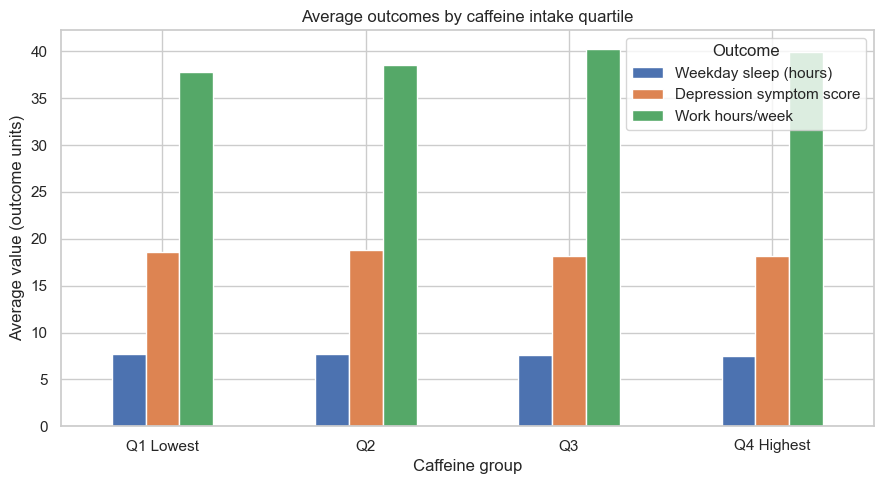

In [15]:
group_means = adult_data.groupby("caffeine_group", observed = False)["weekday_sleep_hours",].mean() if False else adult_data.groupby("caffeine_group", observed = False)[["weekday_sleep_hours","depression_symptom_score","work_hours_last_week"]].mean()
display(group_means.round(2))
fig, ax = plt.subplots(figsize = (9, 5))
group_means.plot(kind = "bar", ax = ax)
ax.set(title = "Average outcomes by caffeine intake quartile", xlabel = "Caffeine group", ylabel = "Average value (outcome units)")
ax.legend(["Weekday sleep (hours)","Depression symptom score","Work hours/week"], title = "Outcome")
plt.xticks(rotation = 0); plt.tight_layout(); plt.savefig(figures_path / "caffeine_group_mean_comparison.png", dpi = 180, bbox_inches = "tight"); plt.show()

Statistical comparison (exploratory)

The Kruskal–Wallis test checks whether the distributions differ across caffeine groups. It is not adjusted for the NHANES survey design or other variables. We use it as a supporting exploratory result, not the final word on statistical significance.

In [16]:
kw_results = []
for outcome in ["weekday_sleep_hours","depression_symptom_score","work_hours_last_week"]:
    groups = [adult_data.loc[adult_data["caffeine_group"] == group, outcome].dropna() for group in ["Q1 Lowest","Q2","Q3","Q4 Highest"]]
    groups = [g for g in groups if len(g)>0]
    if len(groups)>=2:
        statistic, pvalue = kruskal(*groups)
        kw_results.append({"Outcome":outcome,"Kruskal-Wallis statistic":statistic,"p-value":pvalue})
kw_table = pd.DataFrame(kw_results)
display(kw_table.round(4))

,Outcome,Kruskal-Wallis statistic,p-value
0,weekday_sleep_hours,12.1221,0.0070
1,depression_symptom_score,0.3501,0.9503
2,work_hours_last_week,15.7122,0.0013


Adjusted regression models

These models estimate the association between caffeine (in 100-mg increments) and each outcome while adjusting for age, sex, race/ethnicity, education, and family income-to-poverty ratio when available. Weighted least squares uses the Day 1 dietary weight; standard errors are clustered by NHANES primary sampling unit as an approximation. This is not full survey-design inference because strata are not incorporated. Focus on effect sizes and confidence intervals, not just p-values.

All three outcomes are attempted: weekday sleep, depression symptom score, and work hours. If depression is missing from the results table, check the model-skipped table and variable-creation section; this notebook now prints a clear status for each outcome.

Model status for all three planned outcomes:


,Outcome,Status,N,Explanation
0,Weekday sleep (hours),Fitted,4159,Model fitted with caffeine and demographic adj...
1,Depression symptom score,Skipped,26,Fewer than 100 complete cases remain.
2,Work hours last week,Fitted,2273,Model fitted with caffeine and demographic adj...


Caffeine regression coefficients:


,Outcome,Complete-case N,Estimate per 100 mg,95% CI lower,95% CI upper,p-value
0,Weekday sleep (hours),4159,-0.0660,-0.1165,-0.0155,0.0104
1,Work hours last week,2273,0.5055,0.2937,0.7172,0.0000


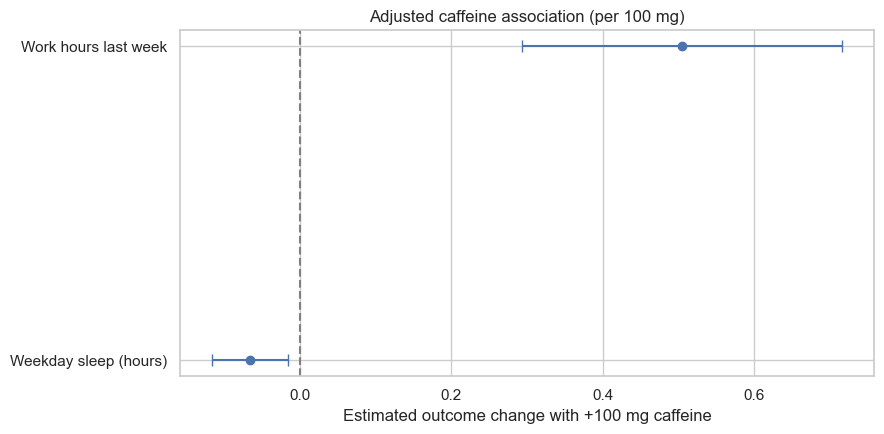

In [17]:
covariates = ["RIDAGEYR", "RIAGENDR", "RIDRETH1", "DMDEDUC2", "INDFMPIR"]
main_outcomes = {
    "weekday_sleep_hours": "Weekday sleep (hours)",
    "depression_symptom_score": "Depression symptom score",
    "work_hours_last_week": "Work hours last week",}
model_results = []
fitted_models = {}
model_status_rows = []
weight_name = "WTDRD1" if "WTDRD1" in adult_data.columns else None
cluster_name = "SDMVPSU" if "SDMVPSU" in adult_data.columns else None

for outcome, outcome_label in main_outcomes.items():
    if outcome not in adult_data.columns:
        model_status_rows.append({"Outcome": outcome_label, "Status": "Not available", "N": 0,
                                 "Explanation": f"Variable {outcome!r} was not created or is missing."})
        continue
    cols = [outcome, "caffeine_day1_mg"] + [c for c in covariates if c in adult_data.columns]
    if weight_name: cols.append(weight_name)
    if cluster_name: cols.append(cluster_name)
    d = adult_data[cols].copy().replace([np.inf, -np.inf], np.nan).dropna()
    if weight_name:
        d = d[d[weight_name] > 0]
    if len(d) < 100:
        model_status_rows.append({"Outcome": outcome_label, "Status": "Skipped", "N": len(d), "Explanation": "Fewer than 100 complete cases remain."})
        continue
    X = d[["caffeine_day1_mg"] + [c for c in covariates if c in d.columns]].copy()
    cats = [c for c in ["RIAGENDR", "RIDRETH1", "DMDEDUC2"] if c in X.columns]
    X = pd.get_dummies(X, columns = cats, drop_first = True, dtype = float).astype(float)
    X["caffeine_per_100mg"] = X.pop("caffeine_day1_mg") / 100
    X = sm.add_constant(X, has_constant="add")
    weights = d[weight_name] if weight_name else None
    if cluster_name:
        fit = sm.WLS(d[outcome], X, weights = weights).fit(
            cov_type = "cluster", cov_kwds = {"groups": d[cluster_name]})
    else:
        fit = sm.WLS(d[outcome], X, weights = weights).fit(cov_type = "HC3")
    fitted_models[outcome] = fit
    term = "caffeine_per_100mg"
    ci = fit.conf_int().loc[term]
    model_results.append({"Outcome": outcome_label, "Complete-case N": len(d),
                         "Estimate per 100 mg": fit.params[term],
                         "95% CI lower": ci.iloc[0], "95% CI upper": ci.iloc[1],
                         "p-value": fit.pvalues[term]})
    model_status_rows.append({"Outcome": outcome_label, "Status": "Fitted", "N": len(d),
                             "Explanation": "Model fitted with caffeine and demographic adjustments."})
model_table = pd.DataFrame(model_results)
model_status_table = pd.DataFrame(model_status_rows)
print("Model status for all three planned outcomes:")
display(model_status_table)
print("Caffeine regression coefficients:")
display(model_table.round(4))

# Forest plot of the caffeine coefficient and its 95% CI.
if not model_table.empty:
    fig, ax = plt.subplots(figsize = (9, max(4.5, 1.2 * len(model_table))))
    y = np.arange(len(model_table))
    estimates = model_table["Estimate per 100 mg"]
    lower = estimates - model_table["95% CI lower"]
    upper = model_table["95% CI upper"] - estimates
    ax.errorbar(estimates, y, xerr = [lower, upper], fmt = "o", capsize = 4)
    ax.axvline(0, linestyle = "--", color = "gray")
    ax.set_yticks(y, model_table["Outcome"])
    ax.set(title = "Adjusted caffeine association (per 100 mg)",
           xlabel = "Estimated outcome change with +100 mg caffeine")
    plt.tight_layout()
    plt.savefig(figures_path / "adjusted_model_forest_plot.png", dpi = 180, bbox_inches = "tight")
    plt.show()



How to read the regression results

The table reports the estimated outcome difference associated with each additional 100 mg of caffeine, after adjusting for the demographic variables listed above.

- Estimate: direction and size of the association, in the outcome's units.
- 95% confidence interval: range of estimates reasonably compatible with the model and data. If it crosses zero, the result is not clearly different from no association at the 5% level.
- p-value: supplementary evidence against a zero association; don't interpret it without the estimate and confidence interval.
- Complete-case N: participants with valid values for every variable included in that particular model. This can differ across outcomes.

This model uses weights and PSU-clustered standard errors but does not incorporate NHANES strata; therefore, it is an approximation rather than full design-based survey inference. The results describe associations, not effects caused by caffeine.


Predicted outcomes at selected caffeine amounts

These predictions use the fitted linear regression models. At each caffeine level (0, 100, 200, etc. mg/day), the code changes caffeine for every participant in the outcome's complete-case model sample, keeps their observed demographic characteristics, predicts their outcome, and averages the predictions. This is population-standardized prediction for that model sample, not a prediction for one specific person. Tables include predicted values and approximate 95% confidence intervals. The curves are limited to the model sample's 95th percentile of caffeine to avoid extreme-tail extrapolation. If a model (including depression) did not fit, it is clearly skipped.

Prediction unavailable for Depression symptom score: its regression did not fit.
Adjusted predicted outcome values at selected caffeine amounts:


,Outcome,Caffeine (mg/day),Predicted average outcome,Approx. 95% CI lower,Approx. 95% CI upper,Model N,Observed 95th percentile caffeine (mg)
0,Weekday sleep (hours),0,7.723,7.671,7.776,4159,455.0
1,Weekday sleep (hours),100,7.657,7.655,7.659,4159,455.0
2,Weekday sleep (hours),200,7.591,7.543,7.640,4159,455.0
3,Weekday sleep (hours),300,7.525,7.426,7.624,4159,455.0
4,Weekday sleep (hours),400,7.459,7.310,7.609,4159,455.0
5,Work hours last week,0,38.821,38.562,39.081,2273,432.0
6,Work hours last week,100,39.327,39.279,39.374,2273,432.0
7,Work hours last week,200,39.832,39.668,39.996,2273,432.0
8,Work hours last week,300,40.338,39.962,40.714,2273,432.0
9,Work hours last week,400,40.843,40.255,41.431,2273,432.0


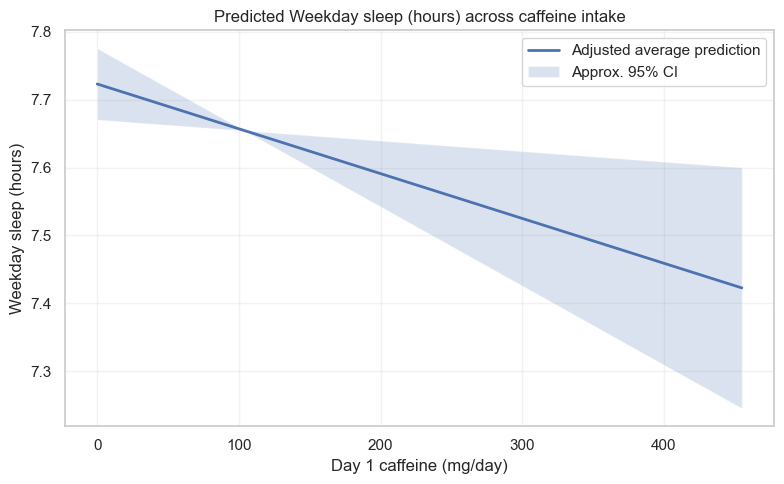

Curve shown through 455.0 mg/day (sample 95th percentile).


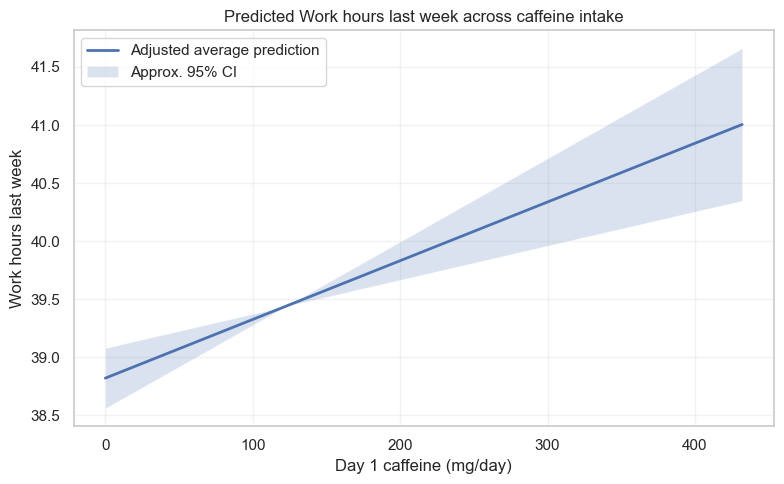

Curve shown through 432.0 mg/day (sample 95th percentile).


In [18]:
# Average adjusted predictions at caffeine values, plus a prediction curve for each fitted outcome.
selected_caffeine_levels = [0, 100, 200, 300, 400, 500]
prediction_rows = []
prediction_curves = {}

for outcome, outcome_label in main_outcomes.items():
    if outcome not in fitted_models:
        print(f"Prediction unavailable for {outcome_label}: its regression did not fit.")
        continue
    fit = fitted_models[outcome]
    design = np.asarray(fit.model.exog, dtype = float)
    design_names = list(fit.model.exog_names)
    caffeine_idx = design_names.index("caffeine_per_100mg")
    params = np.asarray(fit.params, dtype = float)
    covariance = np.asarray(fit.cov_params(), dtype = float)

    # Recreate the same complete-case model sample to identify the observed caffeine range.
    prediction_cols = [outcome, "caffeine_day1_mg"] + [c for c in covariates if c in adult_data.columns]
    if weight_name and weight_name in adult_data.columns: prediction_cols.append(weight_name)
    if cluster_name and cluster_name in adult_data.columns: prediction_cols.append(cluster_name)
    complete_sample = adult_data[prediction_cols].replace([np.inf, -np.inf], np.nan).dropna()
    if weight_name and weight_name in complete_sample:
        complete_sample = complete_sample[complete_sample[weight_name] > 0]
    caffeine_95th = float(complete_sample["caffeine_day1_mg"].quantile(0.95))

    # Continuous curve from zero through the 95th percentile of observed caffeine.
    curve_x = np.linspace(0, caffeine_95th, 101)
    curve_mean, curve_low, curve_high = [], [], []
    for dose in curve_x:
        changed_design = design.copy()
        changed_design[:, caffeine_idx] = dose / 100.0
        mean_design_row = changed_design.mean(axis = 0)
        estimate = float(mean_design_row @ params)
        se = float(np.sqrt(max(0, mean_design_row @ covariance @ mean_design_row.T)))
        curve_mean.append(estimate)
        curve_low.append(estimate - 1.96 * se)
        curve_high.append(estimate + 1.96 * se)
    prediction_curves[outcome] = {"label": outcome_label, "x": curve_x, "mean": np.array(curve_mean), "low": np.array(curve_low), "high": np.array(curve_high), "limit_95": caffeine_95th}

    # Table at fixed doses. Include only doses within the observed 95th-percentile range.
    for dose in selected_caffeine_levels:
        if dose > caffeine_95th:
            continue
        changed_design = design.copy()
        changed_design[:, caffeine_idx] = dose / 100.0
        mean_design_row = changed_design.mean(axis = 0)
        estimate = float(mean_design_row @ params)
        se = float(np.sqrt(max(0, mean_design_row @ covariance @ mean_design_row.T)))
        prediction_rows.append({"Outcome": outcome_label, "Caffeine (mg/day)": dose,
                              "Predicted average outcome": estimate,
                              "Approx. 95% CI lower": estimate - 1.96 * se,
                              "Approx. 95% CI upper": estimate + 1.96 * se,
                              "Model N": int(design.shape[0]),
                              "Observed 95th percentile caffeine (mg)": round(caffeine_95th, 1)})

prediction_table = pd.DataFrame(prediction_rows)
if not prediction_table.empty:
    print("Adjusted predicted outcome values at selected caffeine amounts:")
    display(prediction_table.round(3))
else:
    print("No prediction table: none of the main regression models were fitted.")

# Separate figure per outcome because sleep, symptom score, and work have different units.
for outcome, curve in prediction_curves.items():
    fig, ax = plt.subplots(figsize = (8, 5))
    ax.plot(curve["x"], curve["mean"], linewidth = 2, label = "Adjusted average prediction")
    ax.fill_between(curve["x"], curve["low"], curve["high"], alpha = 0.2, label = "Approx. 95% CI")
    ax.set(title = f"Predicted {curve['label']} across caffeine intake", xlabel = "Day 1 caffeine (mg/day)", ylabel = curve["label"])
    ax.legend(); ax.grid(alpha = 0.25); plt.tight_layout()
    plt.savefig(figures_path / f"predicted_{outcome.replace('_','-')}.png", dpi = 180, bbox_inches = "tight")
    plt.show()
    print(f"Curve shown through {curve['limit_95']:.1f} mg/day (sample 95th percentile).")

## 18. Demographic-adjusted predictions by age group and sex

These plots directly address whether the model-estimated caffeine association looks different across age groups and sex. Each line is an **average predicted outcome within that subgroup**. Caffeine is varied along the x-axis while the subgroup's other demographic characteristics remain represented by the observed participants in that subgroup. These are adjusted model-based associations, not causal effects. The depression outcome is included when its regression model was successfully fitted.

No fitted model for Depression symptom score; subgroup predictions cannot be made.
Subgroup-standardized estimates (predicted outcome levels at selected caffeine amounts):


,Outcome,Grouping,Group,Subgroup N,Predicted at 0 mg,Predicted at 100 mg,Predicted at 200 mg
0,Weekday sleep (hours),Age group,60–79,1310,7.758,7.693,7.628
1,Weekday sleep (hours),Age group,18–29,614,7.640,7.575,7.510
2,Weekday sleep (hours),Age group,45–59,1004,7.713,7.648,7.583
3,Weekday sleep (hours),Age group,30–44,963,7.695,7.630,7.565
4,Weekday sleep (hours),Age group,80+,268,7.880,7.815,7.750
5,Weekday sleep (hours),Sex,Female,2138,7.882,7.817,7.752
6,Weekday sleep (hours),Sex,Male,2021,7.555,7.489,7.424
7,Work hours last week,Age group,60–79,417,37.707,38.216,38.726
8,Work hours last week,Age group,18–29,462,39.911,40.420,40.930
9,Work hours last week,Age group,45–59,681,38.438,38.947,39.457


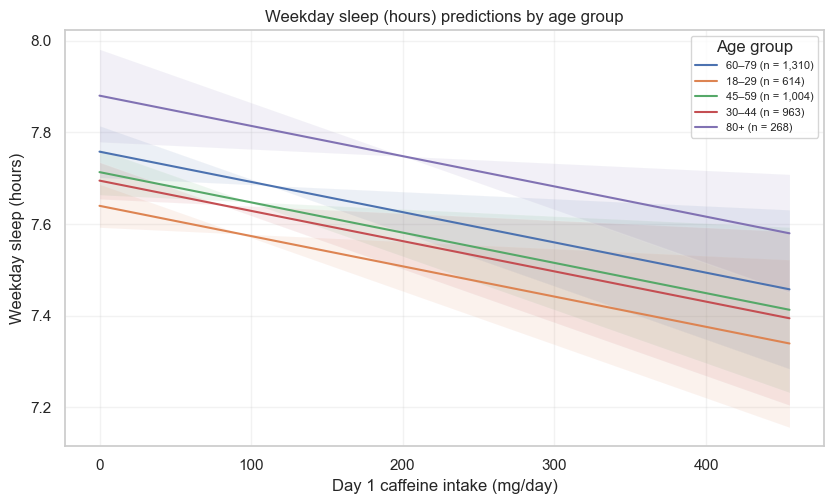

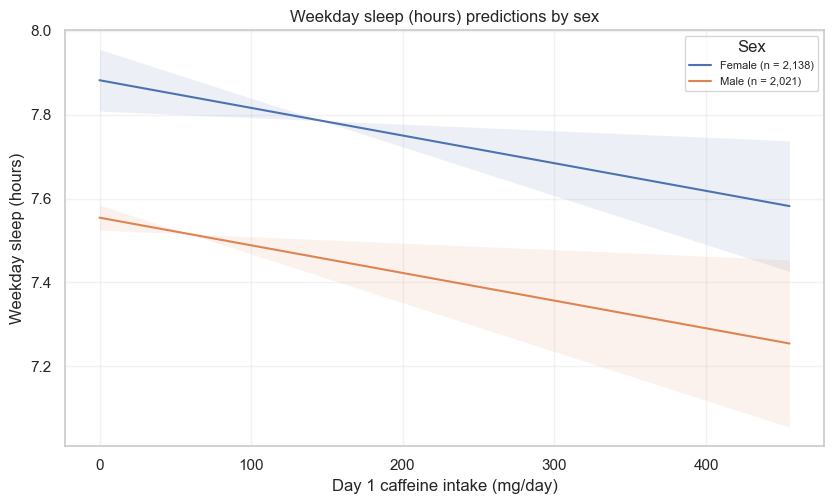

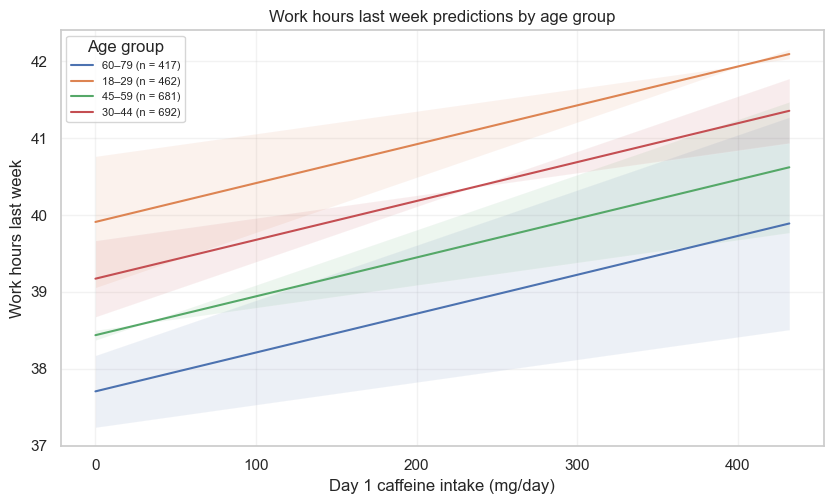

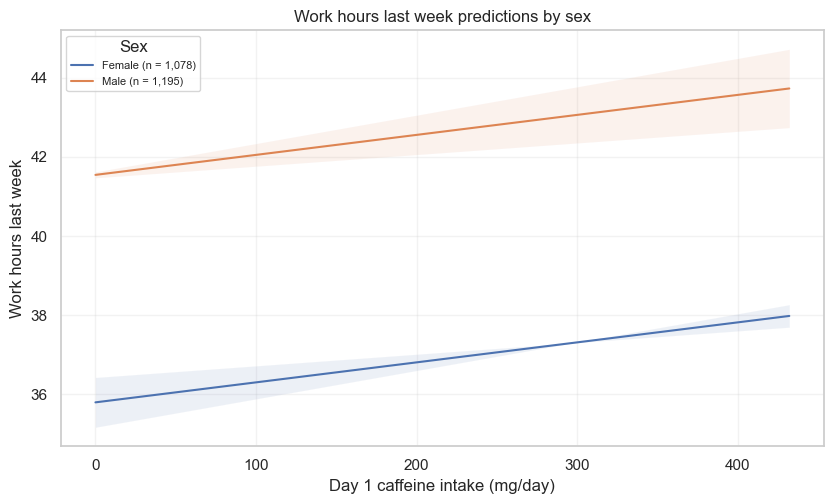

In [19]:
# Subgroup-standardized predictions: age groups and sex, separately for all fitted outcomes.
# For each subgroup, use that subgroup's observed covariate rows; vary caffeine only.
subgroup_prediction_rows = []
subgroup_prediction_curves = {}

age_groups_for_prediction = [g for g in adult_data.get("age_group", pd.Series(dtype="object")).dropna().unique()]
sex_groups_for_prediction = [g for g in adult_data.get("sex_label", pd.Series(dtype="object")).dropna().unique()]

for outcome, outcome_label in main_outcomes.items():
    if outcome not in fitted_models:
        print(f"No fitted model for {outcome_label}; subgroup predictions cannot be made.")
        continue
    fit = fitted_models[outcome]
    model_design = pd.DataFrame(fit.model.exog, columns = fit.model.exog_names)
    model_d = adult_data[[outcome, "caffeine_day1_mg"] + [c for c in covariates if c in adult_data] +
                         ([weight_name] if weight_name and weight_name in adult_data else []) +
                         ([cluster_name] if cluster_name and cluster_name in adult_data else [])].copy()
    model_d = model_d.replace([np.inf, -np.inf], np.nan).dropna()
    if weight_name and weight_name in model_d:
        model_d = model_d[model_d[weight_name] > 0]
    # Model design and complete-case rows have the same order as the fitted model.
    model_design = model_design.reset_index(drop = True)
    caffeine_idx = model_design.columns.get_loc("caffeine_per_100mg")
    x_values = np.linspace(0, min(float(model_d["caffeine_day1_mg"].quantile(.95)), 600), 61)
    curve_store = {}
    
    for grouping, groups in [("Age group", age_groups_for_prediction), ("Sex", sex_groups_for_prediction)]:
        if grouping == "Age group" and "age_group" not in adult_data:
            continue
        if grouping == "Sex" and "sex_label" not in adult_data:
            continue
        group_col = "age_group" if grouping == "Age group" else "sex_label"
        # Align group labels with the complete-case rows used by this outcome model.
        group_labels = adult_data.loc[model_d.index, group_col].reset_index(drop=True)
        for group in groups:
            row_mask = group_labels.eq(group)
            if row_mask.sum() < 30:
                continue
            subgroup_design = model_design.loc[row_mask].to_numpy(dtype = float)
            predictions, lower, upper = [], [], []
            params = np.asarray(fit.params, dtype = float)
            cov = np.asarray(fit.cov_params(), dtype = float)
            for caffeine_mg in x_values:
                changed = subgroup_design.copy()
                changed[:, caffeine_idx] = caffeine_mg / 100.0
                average_row = changed.mean(axis = 0)
                pred = float(average_row @ params)
                se = float(np.sqrt(max(0.0, average_row @ cov @ average_row.T)))
                predictions.append(pred); lower.append(pred-1.96*se); upper.append(pred+1.96*se)
            subgroup_prediction_rows.append({"Outcome": outcome_label, "Grouping": grouping, "Group": group,
                                           "Subgroup N": int(row_mask.sum()),
                                           "Predicted at 0 mg": predictions[0],
                                           "Predicted at 100 mg": predictions[min(range(len(x_values)), key = lambda j: abs(x_values[j]-100))],
                                           "Predicted at 200 mg": predictions[min(range(len(x_values)), key = lambda j: abs(x_values[j]-200))]})
            curve_store[(grouping, str(group))] = (x_values.copy(), np.array(predictions), np.array(lower), np.array(upper), int(row_mask.sum()))
    subgroup_prediction_curves[outcome] = {"label": outcome_label, "curves": curve_store}

# Display a compact table so subgroup estimates are visible as numeric results as well as plots.
by_subgroup_table = pd.DataFrame(subgroup_prediction_rows)

if not by_subgroup_table.empty:
    print("Subgroup-standardized estimates (predicted outcome levels at selected caffeine amounts):")
    display(by_subgroup_table.round(3))
else:
    print("No subgroup prediction results were generated.")

# One outcome per figure; left panel age groups, right panel sex.
for outcome, info in subgroup_prediction_curves.items():
    for grouping in ["Age group", "Sex"]:
        keys = [k for k in info["curves"] if k[0] == grouping]
        if not keys:
            continue
        fig, ax = plt.subplots(figsize=(8.5, 5.2))
        for key in keys:
            x, mean, low, high, n = info["curves"][key]
            ax.plot(x, mean, label=f"{key[1]} (n = {n:,})")
            ax.fill_between(x, low, high, alpha = 0.10)
        ax.set(title = f"{info['label']} predictions by {grouping.lower()}", xlabel = "Day 1 caffeine intake (mg/day)", ylabel = info["label"])
        ax.legend(title = grouping, fontsize = 8)
        ax.grid(alpha = 0.25)
        plt.tight_layout()
        safe_outcome = outcome.replace("_", "-")
        safe_group = grouping.lower().replace(" ", "-")
        plt.savefig(figures_path / f"predicted_{safe_outcome}_by_{safe_group}.png", dpi = 180, bbox_inches = "tight")
        plt.show()


Reading the subgroup prediction results

- Age-group plots: compare the lines to see whether the model-estimated outcome at each caffeine amount differs across age groups.
- Sex plots: compare male and female subgroup-average predicted lines.
- Line slope: shows the fitted caffeine association within that subgroup.
- Line height: shows the subgroup's predicted outcome level, which can differ due to demographic characteristics beyond caffeine.
- Shaded interval: approximate confidence interval for the subgroup mean prediction.

Do not interpret subgroup line differences as caffeine causing changes. These models are observational, and unmeasured factors may influence the patterns.

Sensitivity checks

Two quick checks: (1) use the two-day average caffeine intake for participants with both recall days, and (2) compare caffeine modeled on a log scale. Similar directions across these checks increase confidence that the result is not driven solely by a single modeling choice. These are still approximate analyses.

In [20]:
sensitivity_rows = []
for outcome, label in main_outcomes.items():
    if outcome not in adult_data: continue
    # Two-day mean caffeine model
    exposure = "caffeine_two_day_average_mg"
    cols = [outcome, exposure]+[c for c in covariates if c in adult_data]+(["WTDR2D"] if "WTDR2D" in adult_data else [])+([cluster_name] if cluster_name else [])
    d = adult_data[cols].copy().replace([np.inf,-np.inf],np.nan).dropna()
    wcol = "WTDR2D" if "WTDR2D" in d else weight_name
    if wcol: d = d[d[wcol]>0]
    if len(d)>=100:
        X = d[[exposure]+[c for c in covariates if c in d]]
        X = pd.get_dummies(X,columns = [c for c in ["RIAGENDR","RIDRETH1","DMDEDUC2"] if c in X],drop_first=True,dtype=float).astype(float)
        X["caffeine_per_100mg"] = X.pop(exposure)/100; X = sm.add_constant(X,has_constant = "add")
        fit = sm.WLS(d[outcome],X,weights = d[wcol] if wcol else None).fit(cov_type = "cluster",cov_kwds = {"groups":d[cluster_name]}) if cluster_name else sm.WLS(d[outcome],X,weights = d[wcol] if wcol else None).fit(cov_type="HC3")
        ci = fit.conf_int().loc["caffeine_per_100mg"]
        sensitivity_rows.append({"Outcome":label,"Sensitivity":"Two-day average","N":len(d),"Estimate per 100 mg":fit.params["caffeine_per_100mg"],"CI low":ci.iloc[0],"CI high":ci.iloc[1]})

# Log exposure sensitivity, using Day 1 caffeine.
for outcome,label in main_outcomes.items():
    cols = [outcome,"caffeine_day1_mg"]+[c for c in covariates if c in adult_data]+([weight_name] if weight_name else [])+([cluster_name] if cluster_name else [])
    d = adult_data[cols].copy().replace([np.inf,-np.inf],np.nan).dropna()
    if weight_name: d = d[d[weight_name]>0]
    if len(d)>=100:
        X = d[["caffeine_day1_mg"]+[c for c in covariates if c in d]]
        X = pd.get_dummies(X,columns = [c for c in ["RIAGENDR","RIDRETH1","DMDEDUC2"] if c in X],drop_first = True,dtype = float).astype(float)
        X["log_caffeine"] = np.log1p(X.pop("caffeine_day1_mg")); X = sm.add_constant(X,has_constant = "add")
        fit = sm.WLS(d[outcome],X,weights = d[weight_name] if weight_name else None).fit(cov_type = "cluster",cov_kwds = {"groups":d[cluster_name]}) if cluster_name else sm.WLS(d[outcome],X,weights=d[weight_name] if weight_name else None).fit(cov_type="HC3")
        ci = fit.conf_int().loc["log_caffeine"]
        sensitivity_rows.append({"Outcome":label,"Sensitivity":"Log caffeine","N":len(d),"Estimate per 100 mg":np.nan,"CI low":ci.iloc[0],"CI high":ci.iloc[1]})
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.round(4))

,Outcome,Sensitivity,N,Estimate per 100 mg,CI low,CI high
0,Weekday sleep (hours),Two-day average,3661,-0.0926,-0.1178,-0.0674
1,Work hours last week,Two-day average,1977,0.9555,0.7372,1.1738
2,Weekday sleep (hours),Log caffeine,4159,NaN,-0.0713,-0.0072
3,Work hours last week,Log caffeine,2273,NaN,-0.1680,1.1551


In [21]:
adult_data.to_csv(processed_path / "adult_analysis_dataset.csv",index = False)
for name, table in {"file_check":file_check,"cleaning_summary":cleaning_summary,"lifestyle_availability":lifestyle_availability,"caffeine_group_summary":group_means,"kruskal_tests":kw_table,"main_regression_results":model_table,"model_status":model_status_table,"predicted_outcomes":prediction_table,"subgroup_predictions":by_subgroup_table,"sensitivity_results":sensitivity_table}.items():
    if isinstance(table,pd.DataFrame): table.to_csv(reports_path / f"{name}.csv",index = True)
print("Saved adult analysis data to",processed_path)
print("Saved summary tables to",reports_path)
print("Saved figures to",figures_path)
print("Number of PNG figures saved:",len(list(figures_path.glob("*.png"))))

Saved adult analysis data to C:\Users\Savio\OneDrive\Desktop\DS2\Project 3\data\processed
Saved summary tables to C:\Users\Savio\OneDrive\Desktop\DS2\Project 3\reports
Saved figures to C:\Users\Savio\OneDrive\Desktop\DS2\Project 3\visualizations
Number of PNG figures saved: 15


Final check and limitations

Study limitations
- Cross-sectional survey data cannot establish cause and effect.
- Dietary recalls capture a limited number of days and may not represent usual caffeine intake.
- Missing responses and questionnaire eligibility reduce sample sizes.
- NHANES has a complex sampling design. These weighted regression estimates and PSU-clustered standard errors are approximations; strata are not incorporated. Use dedicated survey-analysis software for design-correct population inference.
- The depression symptom score is a screening measure, not a diagnosis.
- Residual confounding and measurement error may affect results.

Final checklist
Confirm that all 11 files loaded, ID checks passed, derived variables were created, the charts look sensible, and the regression sample sizes are clearly reported. Review any warnings before using results in a final presentation.

Appendix A. Variable-code reference

| Plain-English measure | NHANES source variable(s) |
|---|---|
| Age | `RIDAGEYR` |
| Sex | `RIAGENDR` (1 male, 2 female) |
| Race/ethnicity | `RIDRETH1` |
| Education | `DMDEDUC2` |
| Family income-to-poverty ratio | `INDFMPIR` |
| Day 1 / Day 2 caffeine | `DR1TCAFF`, `DR2TCAFF` |
| Weekday / nonworkday sleep | `SLD012`, `SLD013` |
| Depression symptom items | `DPQ010` through `DPQ090` |
| Work hours last week | `OCQ180` |
| Physical activity / sedentary time | `PAQ605`, `PAQ620`, `PAQ635`, `PAQ650`, `PAQ665`, `PAD680` |
| Alcohol | `ALQ` variables |
| Smoking | `SMQ` variables |
| BMI / waist | `BMXBMI`, `BMXWAIST` |
| Blood pressure | `BPXSY1–4`, `BPXDI1–4` |

This reference helps decode short source names; the source data itself remains unchanged.